# JEOL image data (.img, .map)

Images, typically BF, and elemental maps of elements selected from the periodic table are recorded and stored in during acquisition.

Import required commands and define path were demo data is stored. Adapt this for your installation.

In [5]:
from pathlib import PurePath
from JEOL_eds import JEOL_image
import JEOL_eds.utils as JU

base = PurePath("/home/alxneit/private/src/JEOL_eds")

Load example data, both an image (`data/demo.img`) and an elemental map (`data/demo.map`).

In [6]:
image = JEOL_image(base / "data" / "demo.img")
emap = JEOL_image(base / "data" / "demo.map")

A `JEOL_image` contains the image data (`JEOL_image.image` and some meta data such as

- `JEOL_pts.file_date`: creation date and time (does change, when file is copied). The acquisition date is accessible as `JEOL_eds.image.parameters["Image"]["Created"]` (data format unknown).
- `JEOL_pts.file_name`: file name
- `JEOL_pts.fileformat`: file format (JED-2200:LibJxImageForm)
- `JEOL_pts.file_nm_per_pixel`:: calibration constant (**carefule**, this is based on the nominal magnification, not on the calibrated, actual magnification)
- `JEOL_pts.parameters`: additional meta data

In [7]:
print(f"{image.file_name}: {image.file_date}")
print(f"{emap.file_name}: {emap.file_date}")

/home/alxneit/private/src/JEOL_eds/data/demo.img: 2021-08-13 16:09:06
/home/alxneit/private/src/JEOL_eds/data/demo.map: 2021-08-13 16:09:36


Plot the image and the map (data is stored in `JEOL_image.image`) using the utility function `JEOL_eds.utils.plot_map`.

The image data corresponds to a bright field image. Therefore, we use an inverted grey scale color map. We also clean up the image a bit by removing outliers and apply some smoothing.

For the elemental map we use a fancier color map and no cleaning of the data but 

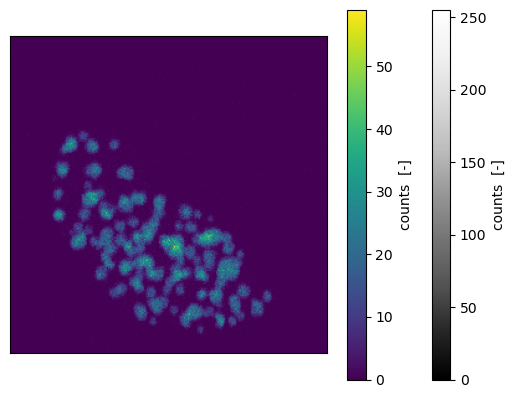

In [8]:
JU.plot_map(image.image, "Greys_r", remove_outliers=True, smooth=True)
JU.plot_map(emap.image, "viridis")